# nb03_profile_lgbm : 뇌 기능 프로파일 지표 · H5 검증 · P1 모델 (M2)

- **가속기 : None (CPU)** · **인터넷 : 불필요**
- **입력** : Dataset `hms-processed`, `hms-src` (**최신 버전**), (선택) 노트북 `Nb04train` Output → 섹션 5 실행
- **출력** : `/kaggle/working/profile/` (지표 CSV, H5 판정표, P1 OOF·지표, 그림)

| 섹션 | 내용 | 코드북 연결 |
|---|---|---|
| 0 | 설정, 입력 탐색 | - |
| 1 | 프로파일 지표 64개 산출 (중앙 10초 파형 + 10분 스펙트로그램, 10/21 수정 지표 12개 포함) | 4-4 지표 7종 |
| 2 | **H5** : 지표가 도메인 지식과 같은 방향인지 효과크기(Cohen's d ≥ 0.5)로 판정 | 가설 H5 |
| 3 | **P1** : 지표 + LightGBM (투표 확률을 가중치로 쓰는 soft label 학습), 환자 단위 5-fold | 성능 목표 단독 KL ≤ 0.50 |
| 4 | 저장 : 결과표 한 줄, 그림 | results.csv |
| 5 | (선택) **E1 + P1 평균 점검** : 두 모델 OOF를 섞었을 때 KL이 내려가는지 (E8 사전 확인) | E8 앙상블 |
| 6 | (선택) **보정 대조군 + E2·P1 평균** : 평균 이득을 보정 효과와 상호보완 효과로 분리 | E8 앙상블 |

## 0. 설정 (목적 : 입력 탐색 / 출력 : SRC_ROOT, PROC_DIR, OUT_DIR)

In [1]:
import sys, os, json, time
from pathlib import Path

def find_root(marker, root="/kaggle/input"):
    for pattern in [f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}", f"*/*/*/*/{marker}"]:
        hits = sorted(Path(root).glob(pattern))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(f"{marker} 를 찾지 못했습니다. Add Input 연결을 확인하세요.")

SRC_ROOT = Path(os.environ.get("HMS_SRC_DIR") or find_root("src/profile/qeeg.py").parents[1])
PROC_DIR = Path(os.environ.get("HMS_PROC_DIR") or find_root("eeg50.npy"))
sys.path.insert(0, str(SRC_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit
from src.config import load_config
from src.data.targets import PROB_COLS, CLASSES
from src.data.folds import check_no_leak
from src.eval.metrics import evaluate
from src.profile.qeeg import profile_features

CFG = load_config(SRC_ROOT / "configs" / "base.yaml")
OUT_DIR = Path(os.environ.get("HMS_OUT_DIR", "/kaggle/working")) / "profile"
OUT_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = os.cpu_count() or 4
print("SRC_ROOT :", SRC_ROOT, "\nPROC_DIR :", PROC_DIR, "\nOUT_DIR  :", OUT_DIR, "| N_JOBS :", N_JOBS)

SRC_ROOT : /kaggle/input/datasets/sungik4057/hms-src 
PROC_DIR : /kaggle/input/datasets/sungik4057/hms-processed/hms_processed 
OUT_DIR  : /kaggle/working/profile | N_JOBS : 4


## 1. 프로파일 지표 산출 (목적 : 판독 관점 지표 7종 / 입력 : eeg50, spec10 / 출력 : feats)

In [2]:
meta = pd.read_csv(PROC_DIR / "meta.csv")
eeg = np.load(PROC_DIR / "eeg50.npy", mmap_mode="r")
spec = np.load(PROC_DIR / "spec10.npy", mmap_mode="r")
assert len(meta) == eeg.shape[0] == spec.shape[0]
check_no_leak(meta)

t0, rows, CHUNK = time.time(), [], 1024
for s in range(0, len(meta), CHUNK):            # 순서대로 덩어리 읽기 (무작위 읽기보다 훨씬 빠름)
    e, sp = np.asarray(eeg[s:s + CHUNK]), np.asarray(spec[s:s + CHUNK])
    rows += Parallel(n_jobs=N_JOBS)(delayed(profile_features)(e[i], sp[i]) for i in range(len(e)))
    print(f"  {min(s + CHUNK, len(meta)):,}/{len(meta):,} | {time.time() - t0:.0f}s", flush=True)

feats = pd.DataFrame(rows)
FEATS = list(feats.columns)
QC = ["nan_ratio", "n_flat", "max_abs"]           # 1단계 품질 지표도 모델 입력에 포함
TGT = PROB_COLS + ["axis_lat", "axis_pd", "axis_mask", "y_seizure_bin"]   # evaluate()가 쓰는 타깃 열
feats = pd.concat([meta[["eeg_id", "patient_id", "fold", "high_vote", "expert_consensus"] + TGT + QC].reset_index(drop=True),
                   feats], axis=1)
assert np.isfinite(feats[FEATS].to_numpy()).all(), "NaN 또는 inf가 있는 지표가 있습니다"
feats.to_csv(OUT_DIR / "profile_features.csv", index=False)
print(f"지표 {len(FEATS)}개 x {len(feats):,}건 | {time.time() - t0:.0f}s")
display(feats[FEATS].describe().T.round(3).head(15))

  1,024/17,089 | 513s
  2,048/17,089 | 942s
  3,072/17,089 | 1462s
  4,096/17,089 | 1919s
  5,120/17,089 | 2493s
  6,144/17,089 | 2932s
  7,168/17,089 | 3362s
  8,192/17,089 | 3788s
  9,216/17,089 | 4213s
  10,240/17,089 | 4634s
  11,264/17,089 | 5052s
  12,288/17,089 | 5475s
  13,312/17,089 | 5896s
  14,336/17,089 | 6361s
  15,360/17,089 | 6910s
  16,384/17,089 | 7451s
  17,089/17,089 | 7843s
지표 64개 x 17,089건 | 7845s


,count,mean,std,min,25%,50%,75%,max
rel_delta,17089.0,0.752,0.151,0.0,0.680,0.782,0.858,0.996
rel_delta_LL,17089.0,0.761,0.163,0.0,0.683,0.799,0.879,0.997
rel_delta_RL,17089.0,0.754,0.163,0.0,0.674,0.791,0.872,0.999
rel_delta_LP,17089.0,0.748,0.164,0.0,0.667,0.781,0.867,0.998
rel_delta_RP,17089.0,0.744,0.164,0.0,0.662,0.777,0.863,0.998
rel_theta,17089.0,0.143,0.085,0.0,0.082,0.126,0.185,0.893
rel_theta_LL,17089.0,0.135,0.088,0.0,0.070,0.115,0.179,0.811
rel_theta_RL,17089.0,0.139,0.089,0.0,0.074,0.120,0.182,0.985
rel_theta_LP,17089.0,0.149,0.094,0.0,0.080,0.130,0.197,0.801
rel_theta_RP,17089.0,0.150,0.094,0.0,0.082,0.130,0.197,0.976


## 2. H5 : 지표가 도메인 지식과 같은 방향인가 (목적 : 지표 타당성 판정 / 출력 : h5_table.csv)

고득표(≥10표) 구간의 최다 득표 클래스로 집단을 나누고, 기대 방향의 효과크기 d ≥ 0.5이면 **지지**로 판정한다.

In [3]:
def cohen_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / (sp + 1e-12)

hv = feats[feats.high_vote == 1].copy()
hv["cls"] = hv.expert_consensus.str.lower()
G = {"편측(LPD+LRDA)": ["lpd", "lrda"], "전반(GPD+GRDA)": ["gpd", "grda"], "PD(LPD+GPD)": ["lpd", "gpd"],
     "RDA(LRDA+GRDA)": ["lrda", "grda"], "Seizure": ["seizure"], "Other": ["other"],
     "Seizure 외 전체": ["lpd", "gpd", "lrda", "grda", "other"]}
grp = lambda name: hv[hv.cls.isin(G[name])]

# (지표, 기대 높은 집단, 비교 집단, 판독 근거)
CHECKS = [
    ("abs_asym_total",       "편측(LPD+LRDA)", "전반(GPD+GRDA)", "편측 패턴은 좌우 파워 비대칭이 크다"),
    ("abs_asym_delta",       "편측(LPD+LRDA)", "전반(GPD+GRDA)", "편측 델타 비대칭"),
    ("period_strength_max",  "PD(LPD+GPD)",    "RDA(LRDA+GRDA)", "주기성 방전은 일정 간격으로 반복된다"),
    ("delta_peak_sharp_max", "RDA(LRDA+GRDA)", "PD(LPD+GPD)",    "율동성 델타는 델타 대역에 뚜렷한 봉우리를 만든다"),
    ("rel_delta",            "RDA(LRDA+GRDA)", "Other",          "RDA는 델타 대역 파워가 우세하다"),
    ("centroid_std_2m",      "Seizure",        "Seizure 외 전체", "발작은 주파수가 시간에 따라 변한다(진화)"),
    ("power_std_10m",        "Seizure",        "Seizure 외 전체", "발작 구간은 파워 변동이 크다"),
    # 10/21 수정 지표 : 1차 H5에서 약했던 주기성·시간 변화의 정의 수정판
    ("period_hf_strength_max",     "PD(LPD+GPD)", "RDA(LRDA+GRDA)",  "[수정] 4~20Hz 성분(뾰족한 방전)의 반복성"),
    ("discharge_prom_max",         "PD(LPD+GPD)", "RDA(LRDA+GRDA)",  "[수정] 방전 사이가 조용할수록 포락선 돌출도가 크다"),
    ("centroid_std_2m_max",        "Seizure",     "Seizure 외 전체", "[수정] 부위 최대 : 국소 발작의 주파수 진화"),
    ("center_ctx_power_absmax",    "Seizure",     "Seizure 외 전체", "[수정] 판정 구간이 앞뒤 2분과 다른 정도(파워)"),
    ("center_ctx_centroid_absmax", "Seizure",     "Seizure 외 전체", "[수정] 판정 구간이 앞뒤 2분과 다른 정도(주파수)"),
]
h5 = []
for feat, hi, lo, why in CHECKS:
    a, b = grp(hi)[feat], grp(lo)[feat]
    d = cohen_d(a, b)
    h5.append({"지표": feat, "기대 : 높은 집단": hi, "비교 집단": lo, "n": f"{len(a)} / {len(b)}",
               "평균(높은)": round(a.mean(), 4), "평균(비교)": round(b.mean(), 4), "Cohen d": round(d, 3),
               "판정": "지지" if d >= 0.5 else ("방향 일치·약함" if d > 0 else "기각"), "판독 근거": why})
h5 = pd.DataFrame(h5)
h5.to_csv(OUT_DIR / "h5_table.csv", index=False)
display(h5)
print(f"H5 지지 {int((h5.판정 == '지지').sum())}/{len(h5)}개 (d ≥ 0.5)")

,지표,기대 : 높은 집단,비교 집단,n,평균(높은),평균(비교),Cohen d,판정,판독 근거
0,abs_asym_total,편측(LPD+LRDA),전반(GPD+GRDA),1467 / 1172,0.4109,0.1531,1.190,지지,편측 패턴은 좌우 파워 비대칭이 크다
1,abs_asym_delta,편측(LPD+LRDA),전반(GPD+GRDA),1467 / 1172,0.4199,0.1628,1.140,지지,편측 델타 비대칭
2,period_strength_max,PD(LPD+GPD),RDA(LRDA+GRDA),1909 / 730,0.3609,0.3089,0.435,방향 일치·약함,주기성 방전은 일정 간격으로 반복된다
3,delta_peak_sharp_max,RDA(LRDA+GRDA),PD(LPD+GPD),730 / 1909,3.1506,2.8695,0.554,지지,율동성 델타는 델타 대역에 뚜렷한 봉우리를 만든다
4,rel_delta,RDA(LRDA+GRDA),Other,730 / 3042,0.8436,0.7573,0.620,지지,RDA는 델타 대역 파워가 우세하다
5,centroid_std_2m,Seizure,Seizure 외 전체,258 / 5681,1.0109,0.7654,0.403,방향 일치·약함,발작은 주파수가 시간에 따라 변한다(진화)
6,power_std_10m,Seizure,Seizure 외 전체,258 / 5681,0.4715,0.3998,0.124,방향 일치·약함,발작 구간은 파워 변동이 크다
7,period_hf_strength_max,PD(LPD+GPD),RDA(LRDA+GRDA),1909 / 730,0.3696,0.3173,0.430,방향 일치·약함,[수정] 4~20Hz 성분(뾰족한 방전)의 반복성
8,discharge_prom_max,PD(LPD+GPD),RDA(LRDA+GRDA),1909 / 730,32.5524,5.1010,0.029,방향 일치·약함,[수정] 방전 사이가 조용할수록 포락선 돌출도가 크다
9,centroid_std_2m_max,Seizure,Seizure 외 전체,258 / 5681,1.3085,1.0505,0.300,방향 일치·약함,[수정] 부위 최대 : 국소 발작의 주파수 진화


H5 지지 6/12개 (d ≥ 0.5)


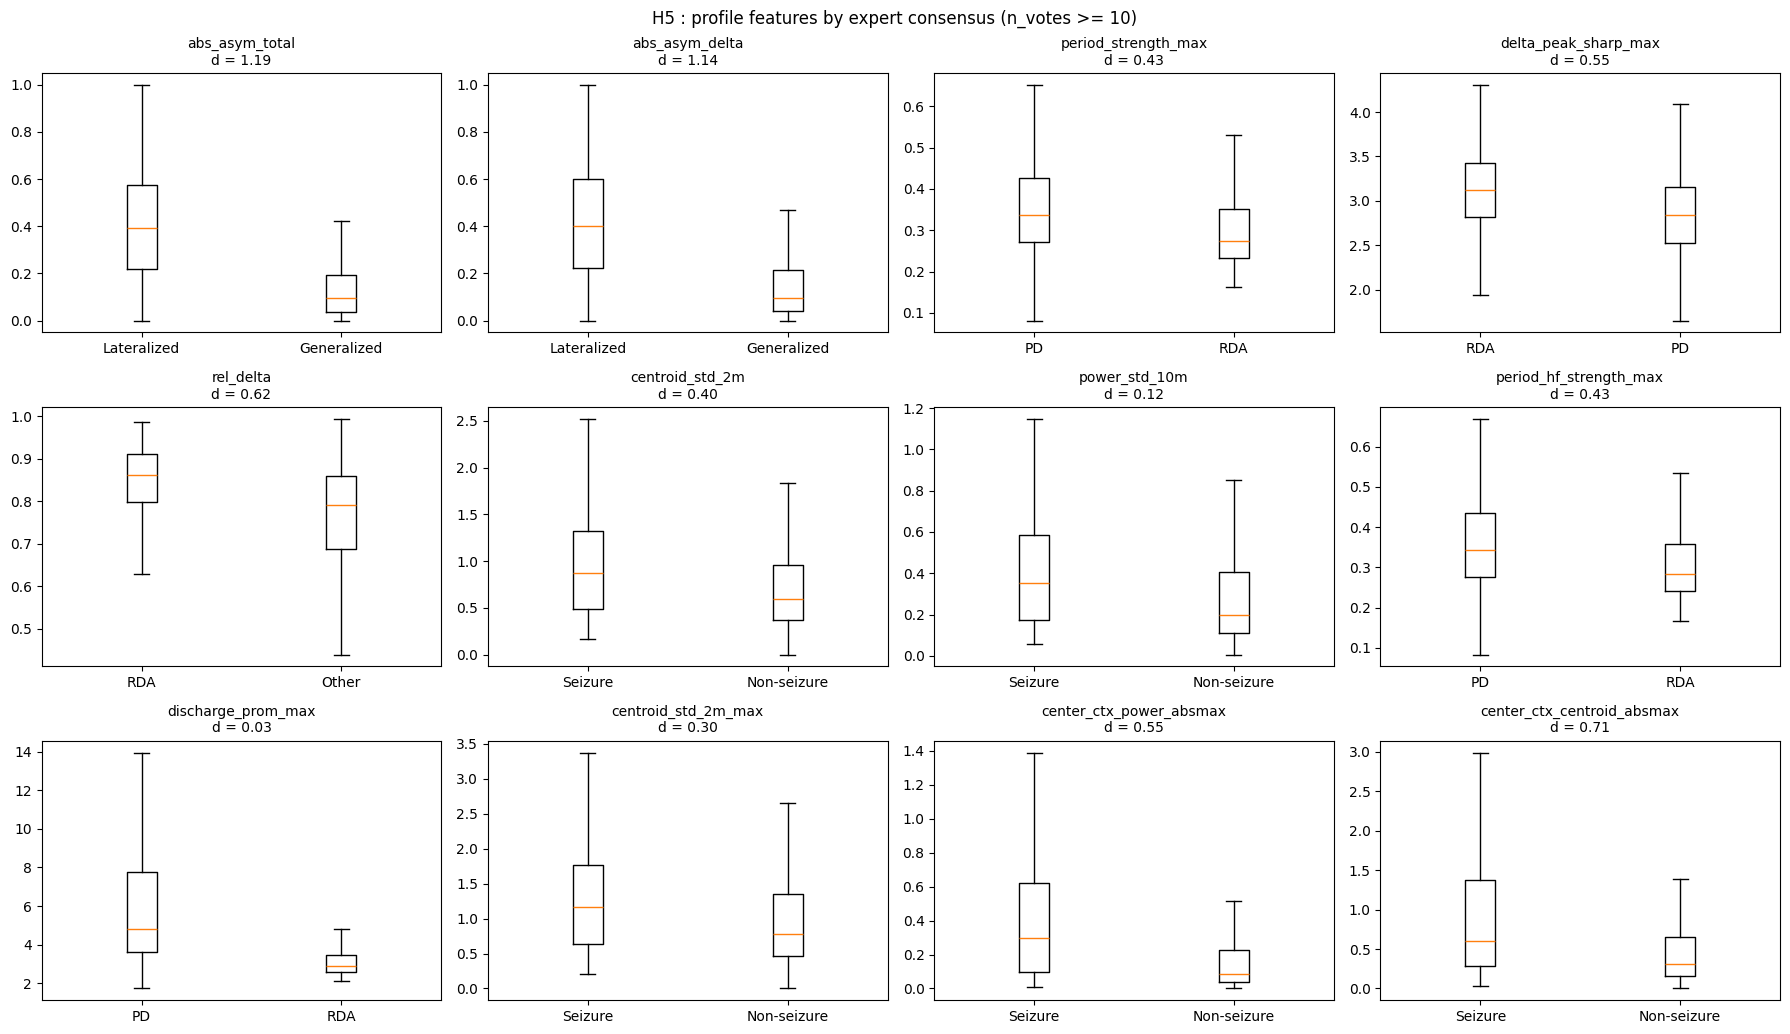

In [4]:
# 분포 그림 : 판정에 쓴 지표의 집단별 상자그림 (이상치 표시 생략, 그래프 글자는 영문)
EN = {"편측(LPD+LRDA)": "Lateralized", "전반(GPD+GRDA)": "Generalized", "PD(LPD+GPD)": "PD", "RDA(LRDA+GRDA)": "RDA",
      "Seizure": "Seizure", "Other": "Other", "Seizure 외 전체": "Non-seizure"}
fig, axes = plt.subplots(3, 4, figsize=(18, 10.5))
for ax, (feat, hi, lo, _) in zip(axes.flat, CHECKS):
    ax.boxplot([grp(hi)[feat], grp(lo)[feat]], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels([EN[hi], EN[lo]])
    d = h5.loc[h5.지표 == feat, "Cohen d"].iloc[0]
    ax.set_title(f"{feat}\nd = {d:.2f}", fontsize=10)
for ax in list(axes.flat)[len(CHECKS):]:
    ax.axis("off")
plt.suptitle("H5 : profile features by expert consensus (n_votes >= 10)")
plt.tight_layout(); plt.savefig(OUT_DIR / "h5_boxplots.png", dpi=110); plt.show()

## 3. P1 : 프로파일 지표 + LightGBM (목적 : 해석 가능한 기준선 / 출력 : p1_oof.csv, p1_metrics.json)

- **soft label 학습** : 한 구간을 6개 클래스 행으로 복제하고 투표 확률을 가중치로 줌 → 가중 교차엔트로피 = KL 최소화와 같은 목표
- **조기 종료** : 학습 fold 안에서 환자 10%를 따로 떼어 사용 (검증 fold 정보 누수 방지)

In [5]:
X_COLS = FEATS + QC
PARAMS = dict(objective="multiclass", num_class=len(CLASSES), learning_rate=0.05, num_leaves=31,
              min_data_in_leaf=40, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=1.0, verbose=-1, num_threads=N_JOBS, seed=CFG["seed"])

def expand(df):
    """구간 1개 → 투표가 있는 클래스마다 1행, 가중치 = 투표 확률."""
    P = df[PROB_COLS].to_numpy()
    r, c = np.nonzero(P > 0)
    return df[X_COLS].to_numpy()[r], c, P[r, c]

oof = np.zeros((len(feats), len(CLASSES)))
importance, t0 = [], time.time()
for k in sorted(feats.fold.unique()):
    tr, va = feats[feats.fold != k], feats[feats.fold == k]
    in_idx, es_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=CFG["seed"]).split(tr, groups=tr.patient_id))
    Xi, yi, wi = expand(tr.iloc[in_idx]); Xe, ye, we = expand(tr.iloc[es_idx])
    booster = lgb.train(PARAMS, lgb.Dataset(Xi, yi, weight=wi), num_boost_round=2000,
                        valid_sets=[lgb.Dataset(Xe, ye, weight=we)],
                        callbacks=[lgb.early_stopping(100, verbose=False)])
    oof[va.index] = booster.predict(va[X_COLS].to_numpy(), num_iteration=booster.best_iteration)
    importance.append(booster.feature_importance("gain"))
    m = evaluate(va, oof[va.index])
    print(f"  fold {k} | rounds {booster.best_iteration} | KL {m['kl_all']:.4f} (고득표 {m['kl_high']:.4f})", flush=True)

metrics = evaluate(feats, oof, target_spec=CFG["eval"]["target_specificity"])
print(f"P1 OOF | KL {metrics['kl_all']:.4f} | 고득표 KL {metrics['kl_high']:.4f} | 편측 AUC {metrics['auc_lat']:.3f} | "
      f"주기성 AUC {metrics['auc_pd']:.3f} | Seizure 민감도 {metrics['sens_at_spec90']:.3f} | {time.time() - t0:.0f}s")
print("목표(단독 KL ≤ 0.50) :", "달성" if metrics["kl_high"] <= 0.50 else "미달", "(고득표 기준)")

  fold 0 | rounds 137 | KL 0.7453 (고득표 0.4803)
  fold 1 | rounds 157 | KL 0.7294 (고득표 0.5341)
  fold 2 | rounds 124 | KL 0.6319 (고득표 0.4486)
  fold 3 | rounds 179 | KL 0.6912 (고득표 0.4782)
  fold 4 | rounds 376 | KL 0.6999 (고득표 0.4902)
P1 OOF | KL 0.6992 | 고득표 KL 0.4865 | 편측 AUC 0.900 | 주기성 AUC 0.898 | Seizure 민감도 0.765 | 47s
목표(단독 KL ≤ 0.50) : 달성 (고득표 기준)


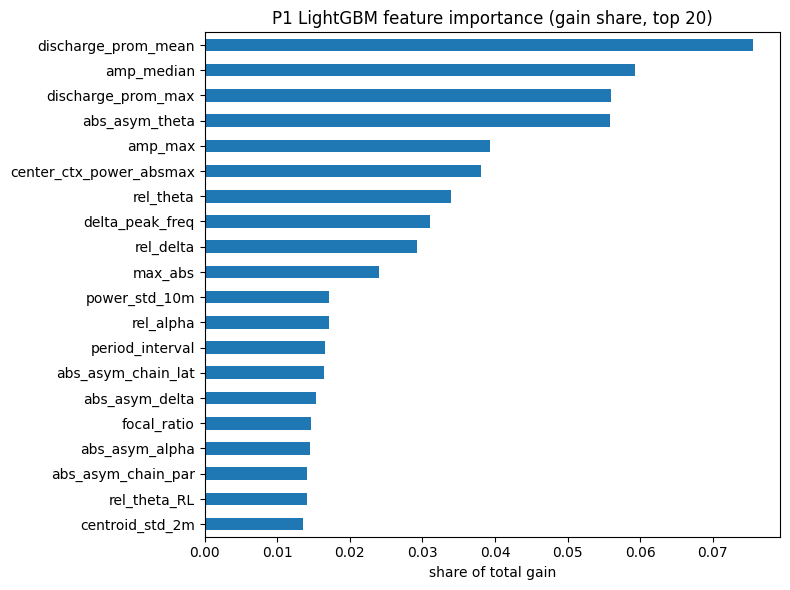

,gain_share
discharge_prom_mean,0.0755
amp_median,0.0593
discharge_prom_max,0.0560
abs_asym_theta,0.0558
amp_max,0.0393
center_ctx_power_absmax,0.0381
rel_theta,0.0340
delta_peak_freq,0.0311
rel_delta,0.0293
max_abs,0.0240


In [6]:
imp = pd.Series(np.mean(importance, axis=0), index=X_COLS).sort_values(ascending=False)
imp_share = (imp / imp.sum()).round(4)
fig, ax = plt.subplots(figsize=(8, 6))
imp_share.head(20)[::-1].plot.barh(ax=ax)
ax.set_title("P1 LightGBM feature importance (gain share, top 20)"); ax.set_xlabel("share of total gain")
plt.tight_layout(); plt.savefig(OUT_DIR / "p1_importance.png", dpi=110); plt.show()
display(imp_share.head(20).to_frame("gain_share"))

## 4. 저장 (목적 : 결과표·OOF 기록 / 출력 : p1_oof.csv, p1_metrics.json, results_row.csv)

In [7]:
pd.concat([feats[["eeg_id", "patient_id", "fold", "high_vote"] + PROB_COLS].reset_index(drop=True),
           pd.DataFrame(oof, columns=[f"pred_{c}" for c in CLASSES])], axis=1).to_csv(OUT_DIR / "p1_oof.csv", index=False)
record = {"exp": "P1", "hypothesis": "H5 / interpretable baseline",
          "change": f"{len(FEATS)} qEEG profile features + 3 QC -> LightGBM (soft label)",
          "cv_kl_all": round(metrics["kl_all"], 4), "cv_kl_high": round(metrics["kl_high"], 4),
          "public_kl": None, "private_kl": None, "auc_lat": round(metrics["auc_lat"], 4), "auc_pd": round(metrics["auc_pd"], 4),
          "sens_at_spec90": round(metrics["sens_at_spec90"], 4), "gpu_hours": 0, "kaggle_version": None,
          "verdict": f"H5 {int((h5.판정 == '지지').sum())}/{len(h5)} supported", "note": "top features: " + ", ".join(imp.index[:5])}
with open(OUT_DIR / "p1_metrics.json", "w") as f:
    json.dump({"record": record, "params": PARAMS, "full": metrics, "importance": imp_share.to_dict()}, f, indent=2, default=float)
pd.DataFrame([record]).to_csv(OUT_DIR / "results_row.csv", index=False)
display(pd.DataFrame([record]).T.rename(columns={0: "P1"}))
print("저장 파일 :", sorted(p.name for p in OUT_DIR.iterdir()))

,P1
exp,P1
hypothesis,H5 / interpretable baseline
change,64 qEEG profile features + 3 QC -> LightGBM (s...
cv_kl_all,0.6992
cv_kl_high,0.4865
public_kl,None
private_kl,None
auc_lat,0.8999
auc_pd,0.8985
sens_at_spec90,0.765


저장 파일 : ['h5_boxplots.png', 'h5_table.csv', 'p1_importance.png', 'p1_metrics.json', 'p1_oof.csv', 'profile_features.csv', 'results_row.csv']


## 5. (선택) E1 + P1 평균 점검 (목적 : 앙상블 효과 사전 확인 / 입력 : Nb04train Output의 models/E1/oof.csv)

- 가중치 0.5(사전에 정한 값)를 판정 기준으로 쓰고, 가중치 곡선은 참고만 한다 (OOF로 가중치를 고르면 낙관적이기 때문)

In [8]:
e1_hits = sorted(Path("/kaggle/input").glob("**/models/E1/oof.csv")) if Path("/kaggle/input").exists() else []
e1_path = Path(os.environ["HMS_E1_OOF"]) if os.environ.get("HMS_E1_OOF") else (e1_hits[0] if e1_hits else None)
if e1_path is None:
    print("E1 OOF 없음 → 건너뜀 (Add Input에서 Nb04train 노트북을 연결하면 실행됨)")
else:
    e1 = pd.read_csv(e1_path)
    PRED = [f"pred_{c}" for c in CLASSES]
    p1 = pd.concat([feats[["eeg_id"] + TGT + ["high_vote", "fold"]], pd.DataFrame(oof, columns=PRED)], axis=1)
    mg = p1.merge(e1[["eeg_id"] + PRED], on="eeg_id", suffixes=("_p1", "_e1"))
    a, b = mg[[f"{c}_p1" for c in PRED]].to_numpy(), mg[[f"{c}_e1" for c in PRED]].to_numpy()
    rows_w = []
    for w in np.round(np.linspace(0, 1, 11), 1):            # w = E1 비중
        m = evaluate(mg, w * b + (1 - w) * a)
        rows_w.append({"E1 비중": w, "KL": round(m["kl_all"], 4), "고득표 KL": round(m["kl_high"], 4)})
    curve = pd.DataFrame(rows_w)
    display(curve.T)
    e1_only, half = curve.loc[curve["E1 비중"] == 1.0].iloc[0], curve.loc[curve["E1 비중"] == 0.5].iloc[0]
    gain = e1_only["고득표 KL"] - half["고득표 KL"]
    print(f"매칭 {len(mg):,}건 | E1 단독 고득표 KL {e1_only['고득표 KL']:.4f} → 0.5:0.5 평균 {half['고득표 KL']:.4f} "
          f"(개선 {gain:+.4f}) → {'앙상블 효과 있음' if gain > 0 else '효과 없음'}")
    curve.to_csv(OUT_DIR / "blend_e1_p1.csv", index=False)

E1 OOF 없음 → 건너뜀 (Add Input에서 Nb04train 노트북을 연결하면 실행됨)


## 6. 보정 대조군 + E2·P1 평균 (목적 : 앙상블 이득이 '보정 효과'인지 '상호보완 정보'인지 분리 / 입력 : models/E1·E2/oof.csv)

- **문제** : 0.5:0.5 평균은 확률을 덜 극단적으로 만든다. E1처럼 과신(overconfident)한 모델이면, P1 정보가 없어도 평균만으로 KL이 내려갈 수 있다.
- **대조군** : temperature scaling `p_T = softmax(log p / T)`. 모델 순위는 그대로 두고 확신 정도만 조정한다.
- **누수 방지** : fold k의 T는 **나머지 fold의 OOF 고득표 구간**으로만 맞춘다 (모델 선택 기준과 같은 고득표 KL).
- **입력** : Input에 없는 실험의 OOF는 **kagglehub로 Nb04_train 이전 버전 Output에서 자동으로 받는다** (설정 → Internet ON)
- **판정** : 보정한 단독 모델(E_T)보다 보정한 평균(0.5·E_T + 0.5·P1_T)의 고득표 KL이 낮으면 **상호보완 효과 있음**.

In [9]:
from scipy.optimize import minimize_scalar
from src.eval.metrics import kl_divergence

PRED = [f"pred_{c}" for c in CLASSES]

NB04_HANDLE = "sungik4057/nb04-train"   # Nb04_train 노트북 (kagglehub로 이전 버전 Output을 직접 받을 때 사용)
NB04_VERSIONS = range(1, 11)             # 확인할 버전 (E1 버전 번호를 알면 [번호]로 지정)
FETCH_TIMEOUT = 60                       # 버전 1개당 최대 대기 시간(초) : 응답 없으면 다음 버전으로

import signal, socket

class _FetchTimeout(Exception):
    pass

def _on_alarm(*_):
    raise _FetchTimeout()

def internet_on(host="www.kaggle.com", port=443, timeout=5):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

def fetch_oof(exp):
    """Input에 없으면 kagglehub로 Nb04_train 버전 Output에서 models/<exp>/oof.csv를 받는다 (인터넷 ON 필요, 버전당 시간 제한)."""
    if not internet_on():
        print(f"  {exp} : 인터넷 OFF → kagglehub 다운로드 건너뜀 (설정에서 Internet ON)")
        return None
    # Kaggle 안에서 kagglehub 기본 동작은 '노트북에 Input으로 붙이고 마운트될 때까지 무한 대기'(while/sleep)라서
    # Save Version(배치) 실행에서는 끝나지 않는다 → 캐시 연결을 끄고 HTTP로 직접 내려받게 한다.
    os.environ["DISABLE_KAGGLE_CACHE"] = "1"
    try:
        import kagglehub
    except ImportError:
        print("  kagglehub 미설치 → 건너뜀")
        return None
    t0 = time.time()
    for v in NB04_VERSIONS:
        signal.signal(signal.SIGALRM, _on_alarm)
        signal.alarm(FETCH_TIMEOUT)
        try:
            got = Path(kagglehub.notebook_output_download(f"{NB04_HANDLE}/versions/{v}", path=f"models/{exp}/oof.csv"))
        except Exception as err:                              # 없는 버전, 해당 실험 없음, 시간 초과
            print(f"  {exp} v{v} : 없음 ({type(err).__name__}) | {time.time() - t0:.0f}s", flush=True)
            continue
        finally:
            signal.alarm(0)
        hit = got if got.is_file() else next(iter(sorted(got.glob("**/oof.csv"))), None)
        if hit is not None:
            print(f"{exp} OOF : kagglehub {NB04_HANDLE} v{v} → {hit} | {time.time() - t0:.0f}s")
            return hit
    return None

def find_oof(exp):
    env = os.environ.get(f"HMS_{exp}_OOF")
    if env:
        return Path(env)
    root = Path("/kaggle/input")
    if not root.exists():
        return None
    for pat in [f"**/models/{exp}/oof.csv", f"**/{exp}_oof.csv", f"**/oof_{exp}.csv"]:   # 노트북 Output 또는 업로드 Dataset(hms-oof)
        hits = sorted(root.glob(pat))
        if hits:
            return hits[0]
    return fetch_oof(exp)

def temp(p, T):
    z = np.log(np.clip(p, 1e-7, 1)) / T
    z = np.exp(z - z.max(axis=1, keepdims=True))
    return z / z.sum(axis=1, keepdims=True)

def fit_T(y, p):
    return minimize_scalar(lambda T: kl_divergence(y, temp(p, T)), bounds=(0.3, 5.0), method="bounded").x

def cv_temperature(df, p):
    """fold별로 나머지 fold 고득표 구간에서 T를 맞춰 적용 → 누수 없는 보정 OOF와 fold별 T."""
    out, Ts = np.zeros_like(p), {}
    y, hv, fold = df[PROB_COLS].to_numpy(), df["high_vote"].to_numpy().astype(bool), df["fold"].to_numpy()
    for k in np.unique(fold):
        fit = (fold != k) & hv
        Ts[int(k)] = fit_T(y[fit], p[fit])
        out[fold == k] = temp(p[fold == k], Ts[int(k)])
    return out, Ts

base = pd.concat([feats[["eeg_id"] + TGT + ["high_vote", "fold"]].reset_index(drop=True),
                  pd.DataFrame(oof, columns=PRED)], axis=1)

rows, records = [], []
for exp in ["E1", "E2"]:
    path = find_oof(exp)
    if path is None:
        print(f"{exp} OOF 없음 → 건너뜀 (Input 연결 또는 인터넷 ON 후 kagglehub 자동 다운로드 필요)")
        continue
    e = pd.read_csv(path)[["eeg_id"] + PRED]
    mg = base.merge(e, on="eeg_id", suffixes=("_p1", "_dl")).reset_index(drop=True)
    p1_raw = mg[[f"{c}_p1" for c in PRED]].to_numpy()
    dl_raw = mg[[f"{c}_dl" for c in PRED]].to_numpy()
    p1_c, T_p1 = cv_temperature(mg, p1_raw)
    dl_c, T_dl = cv_temperature(mg, dl_raw)
    cand = {
        f"{exp} 단독":               dl_raw,
        f"{exp} + T (보정 대조군)":   dl_c,
        "P1v2 단독":                 p1_raw,
        "P1v2 + T":                  p1_c,
        f"0.5·{exp} + 0.5·P1v2":     0.5 * dl_raw + 0.5 * p1_raw,
        f"0.5·{exp}_T + 0.5·P1v2_T": 0.5 * dl_c + 0.5 * p1_c,
    }
    res = {}
    for name, pr in cand.items():
        m = evaluate(mg, pr, target_spec=CFG["eval"]["target_specificity"])
        res[name] = m
        rows.append({"비교군": exp, "모델": name, "KL": round(m["kl_all"], 4), "고득표 KL": round(m["kl_high"], 4),
                     "편측 AUC": round(m["auc_lat"], 4), "주기성 AUC": round(m["auc_pd"], 4),
                     "Seizure 민감도": round(m["sens_at_spec90"], 4)})
    k_raw, k_T = res[f"{exp} 단독"]["kl_high"], res[f"{exp} + T (보정 대조군)"]["kl_high"]
    k_bl, k_blT = res[f"0.5·{exp} + 0.5·P1v2"]["kl_high"], res[f"0.5·{exp}_T + 0.5·P1v2_T"]["kl_high"]
    gain_total, gain_cal, gain_comp = k_raw - k_bl, k_raw - k_T, k_T - k_blT
    share = gain_cal / gain_total if gain_total > 0 else float("nan")
    print(f"\n[{exp}] 매칭 {len(mg):,}건 | fold별 T {dict((k, round(float(v), 2)) for k, v in T_dl.items())} "
          f"| P1 T {dict((k, round(float(v), 2)) for k, v in T_p1.items())} (T > 1 : 과신을 누그러뜨림)")
    print(f"  평균 이득(원본)         {gain_total:+.4f}  = {k_raw:.4f} → {k_bl:.4f}")
    print(f"  보정만으로 얻는 이득     {gain_cal:+.4f}  = {k_raw:.4f} → {k_T:.4f}  (평균 이득의 {share:.0%})")
    print(f"  보정 후 남는 상호보완 이득 {gain_comp:+.4f}  = {k_T:.4f} → {k_blT:.4f}  → "
          f"{'상호보완 효과 있음' if gain_comp > 0 else '상호보완 효과 없음 (평균 이득은 보정 효과)'}")
    for tag, name, chg in [(f"C{exp[-1]}", f"{exp} + T (보정 대조군)", f"{exp} OOF temperature scaling (T fit on other folds, high-vote)"),
                           (f"B{exp[-1]}c", f"0.5·{exp}_T + 0.5·P1v2_T", f"0.5*{exp}_T + 0.5*P1v2_T (both calibrated)")] + \
                          ([("B2", "0.5·E2 + 0.5·P1v2", "0.5*E2 + 0.5*P1v2 OOF (weight pre-specified)")] if exp == "E2" else []):
        m = res[name]
        records.append({"exp": tag, "hypothesis": "calibration control" if tag.startswith("C") else "E8 preview",
                        "change": chg, "cv_kl_all": round(m["kl_all"], 4), "cv_kl_high": round(m["kl_high"], 4),
                        "public_kl": None, "private_kl": None, "auc_lat": round(m["auc_lat"], 4),
                        "auc_pd": round(m["auc_pd"], 4), "sens_at_spec90": round(m["sens_at_spec90"], 4),
                        "gpu_hours": 0, "kaggle_version": None,
                        "verdict": f"complementary gain {gain_comp:+.4f} after calibration" if tag.startswith("B") else
                                   f"calibration gain {gain_cal:+.4f} ({share:.0%} of blend gain)",
                        "note": f"T per fold: {dict((k, round(float(v), 2)) for k, v in T_dl.items())}"})

if rows:
    calib = pd.DataFrame(rows)
    display(calib)
    calib.to_csv(OUT_DIR / "calib_blend.csv", index=False)
    pd.DataFrame(records).to_csv(OUT_DIR / "results_rows_calib.csv", index=False)
    print("저장 : calib_blend.csv, results_rows_calib.csv")

100%|██████████| 2.07M/2.07M [00:00<00:00, 2.21MB/s]


E1 OOF : kagglehub sungik4057/nb04-train v1 → /root/.cache/kagglehub/notebooks/sungik4057/nb04-train/output/versions/1/models/E1/oof.csv | 2s

[E1] 매칭 17,089건 | fold별 T {0: 1.34, 1: 1.31, 2: 1.34, 3: 1.33, 4: 1.34} | P1 T {0: 1.16, 1: 1.15, 2: 1.18, 3: 1.16, 4: 1.12} (T > 1 : 과신을 누그러뜨림)
  평균 이득(원본)         +0.1063  = 0.5008 → 0.3944
  보정만으로 얻는 이득     +0.0339  = 0.5008 → 0.4669  (평균 이득의 32%)
  보정 후 남는 상호보완 이득 +0.0620  = 0.4669 → 0.4049  → 상호보완 효과 있음

[E2] 매칭 17,089건 | fold별 T {0: 1.12, 1: 1.09, 2: 1.12, 3: 1.12, 4: 1.13} | P1 T {0: 1.16, 1: 1.15, 2: 1.18, 3: 1.16, 4: 1.12} (T > 1 : 과신을 누그러뜨림)
  평균 이득(원본)         +0.0287  = 0.3847 → 0.3560
  보정만으로 얻는 이득     +0.0043  = 0.3847 → 0.3804  (평균 이득의 15%)
  보정 후 남는 상호보완 이득 +0.0153  = 0.3804 → 0.3650  → 상호보완 효과 있음


,비교군,모델,KL,고득표 KL,편측 AUC,주기성 AUC,Seizure 민감도
0,E1,E1 단독,0.6910,0.5008,0.9121,0.8979,0.7705
1,E1,E1 + T (보정 대조군),0.6768,0.4669,0.9123,0.8985,0.7814
2,E1,P1v2 단독,0.6992,0.4865,0.8999,0.8985,0.7650
3,E1,P1v2 + T,0.6980,0.4786,0.9000,0.8987,0.7705
4,E1,0.5·E1 + 0.5·P1v2,0.5950,0.3944,0.9298,0.9233,0.8251
5,E1,0.5·E1_T + 0.5·P1v2_T,0.6177,0.4049,0.9307,0.9244,0.8415
6,E2,E2 단독,0.6865,0.3847,0.9208,0.9068,0.8962
7,E2,E2 + T (보정 대조군),0.6806,0.3804,0.9209,0.9069,0.8962
8,E2,P1v2 단독,0.6992,0.4865,0.8999,0.8985,0.7650
9,E2,P1v2 + T,0.6980,0.4786,0.9000,0.8987,0.7705


저장 : calib_blend.csv, results_rows_calib.csv


## 다음 단계
- 공유할 결과 : 섹션 2의 **H5 판정표**(1차·수정 지표 비교)와 상자그림, 섹션 3의 **P1 OOF 한 줄**, 중요도 상위 지표, 섹션 5 결과, **섹션 6 이득 분해 3줄(E1·E2)과 비교표**
- H5 미지지 지표는 정의를 수정해 재산출하거나 추론 로직(R1) 근거에서 제외 (코드북 4-4 기준)
- P1 OOF는 E8 앙상블과 추론 로직(R1)의 입력으로 사용